# Will This Visitor Buy? Purchase Intent Prediction

NextGen Institute, Machine Learning final project.

Most visitors of an online shop leave without buying. In this project we predict, from a browsing session, if the visitor will buy. The shop can then show a coupon or a chat assistant only when it makes sense.

Data: Online Shoppers Purchasing Intention (UCI), https://archive.ics.uci.edu/dataset/468

In [1]:
import json
import inspect
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             ConfusionMatrixDisplay, RocCurveDisplay, classification_report)
from sklearn.inspection import permutation_importance

from helpers import add_features, suggest_action

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
pd.set_option("display.max_colwidth", None)

RANDOM_STATE = 42

## 1. Problem framing

**Who has the problem:** an online shop. Most sessions end without a purchase, and a discount for every visitor is expensive.

**Decision the model supports:** for each session, show nothing, show a coupon, or open a chat assistant.

**Target:** `Revenue` (1 = the session ended with a purchase, 0 = no purchase).

**Metric:** we compare models with ROC-AUC, then we look at recall and F1 at a chosen threshold. Only about 15% of the sessions are purchases, so accuracy alone is misleading. A model that always says "no purchase" would be right most of the time and still be useless.

## 2. Data understanding

Each row is one browsing session.

In [2]:
df = pd.read_csv("online_shoppers_intention.csv")
print("Rows and columns:", df.shape)
df.head()

Rows and columns: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


**Column dictionary**

| Column | Meaning |
|---|---|
| Administrative, Informational, ProductRelated | Number of pages visited in each page type |
| Administrative_Duration, Informational_Duration, ProductRelated_Duration | Time spent on each page type (seconds) |
| BounceRates | Share of visits that leave after one page (average over the pages visited) |
| ExitRates | Share of page views that were the last page of the session (average) |
| PageValues | Average value of the pages visited before a purchase, calculated by the site |
| SpecialDay | How close the visit is to a special day, from 0 to 1 |
| Month | Month of the visit |
| OperatingSystems, Browser, Region, TrafficType | Numeric codes |
| VisitorType | New_Visitor, Returning_Visitor or Other |
| Weekend | True if the visit was on a weekend |
| Revenue | Target. True if the session ended with a purchase |

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [4]:
# Revenue and Weekend are True/False, we change them to 1/0
df["Revenue"] = df["Revenue"].astype(int)
df["Weekend"] = df["Weekend"].astype(int)

In [5]:
duration_cols = ["Administrative_Duration", "Informational_Duration", "ProductRelated_Duration"]

print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Negative durations:", (df[duration_cols] < 0).sum().sum())

Missing values: 0
Duplicate rows: 125
Negative durations: 0


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


In [7]:
print(df["Revenue"].value_counts())
print()
print(df["Revenue"].value_counts(normalize=True).round(3))

Revenue
0    10422
1     1908
Name: count, dtype: int64

Revenue
0    0.845
1    0.155
Name: proportion, dtype: float64


**What we found**

- There are no missing values. We still handle them in the pipeline, in case new data has some.
- Some rows are exact duplicates. We remove them in preprocessing.
- A duration can not be negative. The check above shows how many there are. We set them to 0 later.
- The classes are imbalanced. Most sessions have no purchase.

## 3. Exploratory data analysis

### Univariate analysis

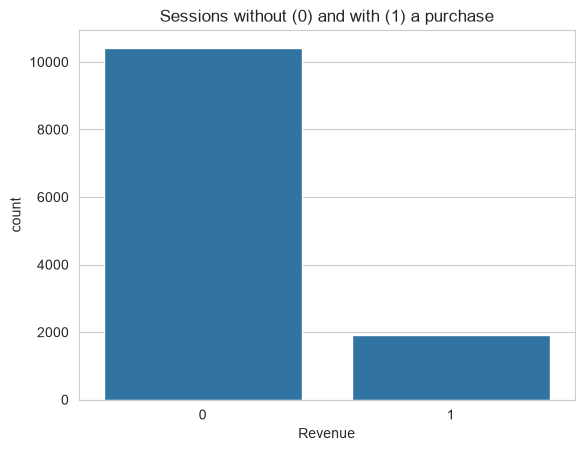

In [8]:
sns.countplot(x="Revenue", data=df)
plt.title("Sessions without (0) and with (1) a purchase")
plt.show()

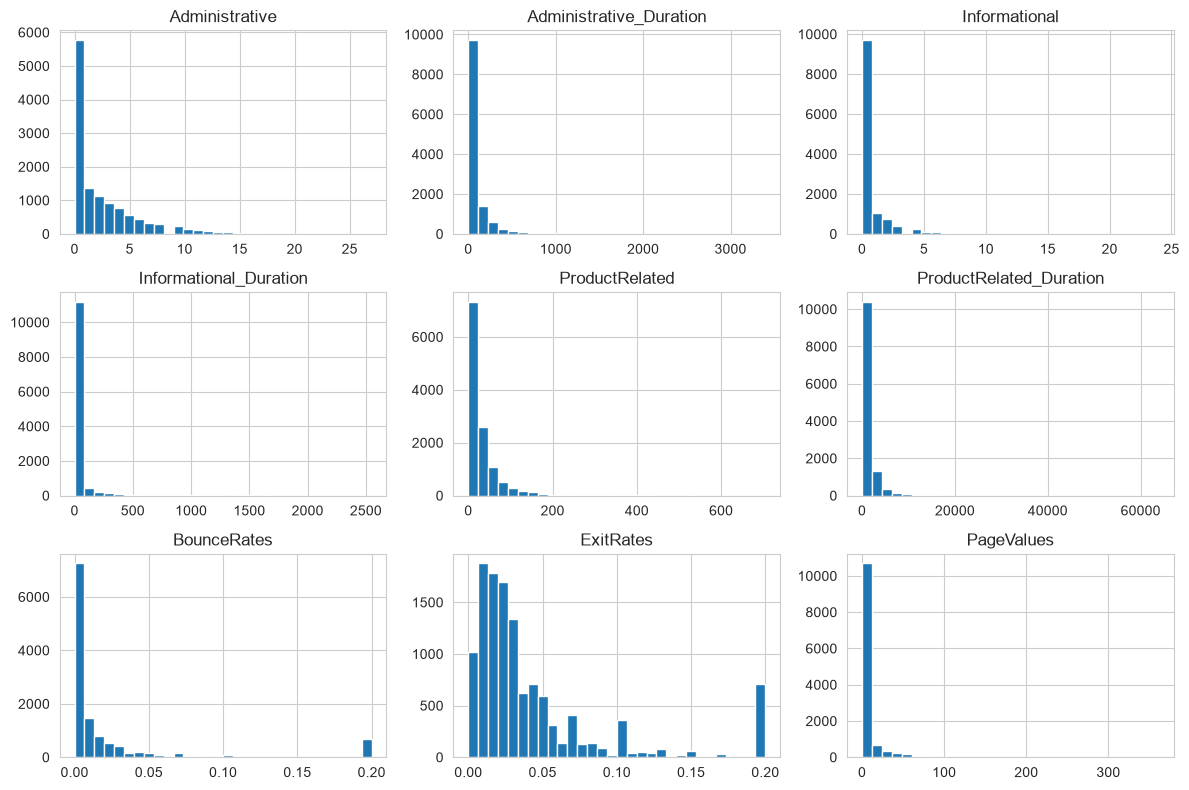

In [9]:
num_cols = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
            "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues"]

df[num_cols].hist(bins=30, figsize=(12, 8))
plt.tight_layout()
plt.show()

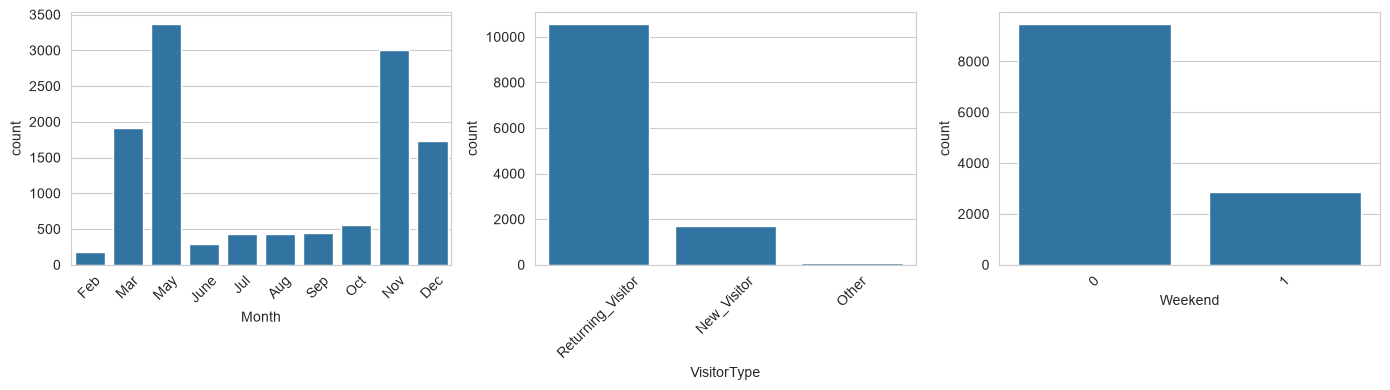

In [10]:
month_order = [m for m in ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
               if m in df["Month"].unique()]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["Month", "VisitorType", "Weekend"]):
    order = month_order if col == "Month" else None
    sns.countplot(x=col, data=df, order=order, ax=ax)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

Most numeric columns have many zeros and a few very large values. `PageValues` is 0 for most sessions. Most visitors are returning visitors.

### Bivariate analysis

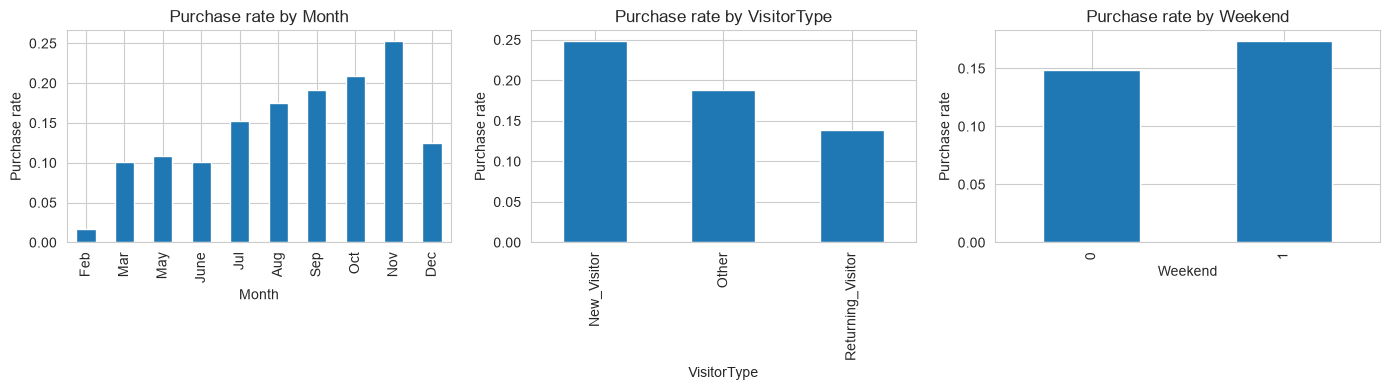

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["Month", "VisitorType", "Weekend"]):
    rate = df.groupby(col)["Revenue"].mean()
    if col == "Month":
        rate = rate.reindex(month_order)
    rate.plot(kind="bar", ax=ax)
    ax.set_ylabel("Purchase rate")
    ax.set_title("Purchase rate by " + col)
plt.tight_layout()
plt.show()

In [12]:
# average of each numeric column for sessions without and with a purchase
df.groupby("Revenue")[num_cols].mean().T.round(2)

Revenue,0,1
Administrative,2.12,3.39
Administrative_Duration,73.74,119.48
Informational,0.45,0.79
Informational_Duration,30.24,57.61
ProductRelated,28.71,48.21
ProductRelated_Duration,1069.99,1876.21
BounceRates,0.03,0.01
ExitRates,0.05,0.02
PageValues,1.98,27.26


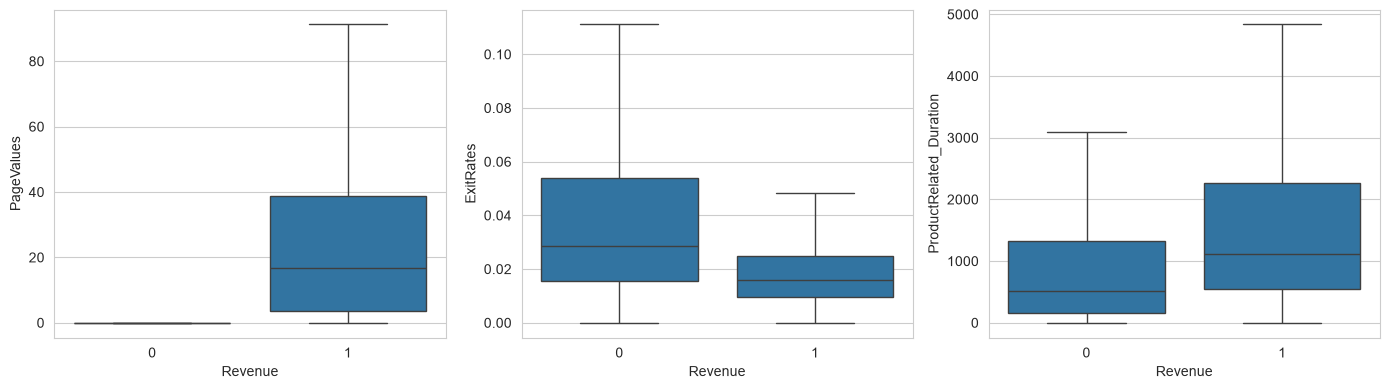

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["PageValues", "ExitRates", "ProductRelated_Duration"]):
    sns.boxplot(x="Revenue", y=col, data=df, showfliers=False, ax=ax)
plt.tight_layout()
plt.show()

In [14]:
zero = df["PageValues"] == 0
print("Purchase rate when PageValues = 0:", round(df.loc[zero, "Revenue"].mean(), 3))
print("Purchase rate when PageValues > 0:", round(df.loc[~zero, "Revenue"].mean(), 3))

Purchase rate when PageValues = 0: 0.039
Purchase rate when PageValues > 0: 0.563


### Multivariate analysis

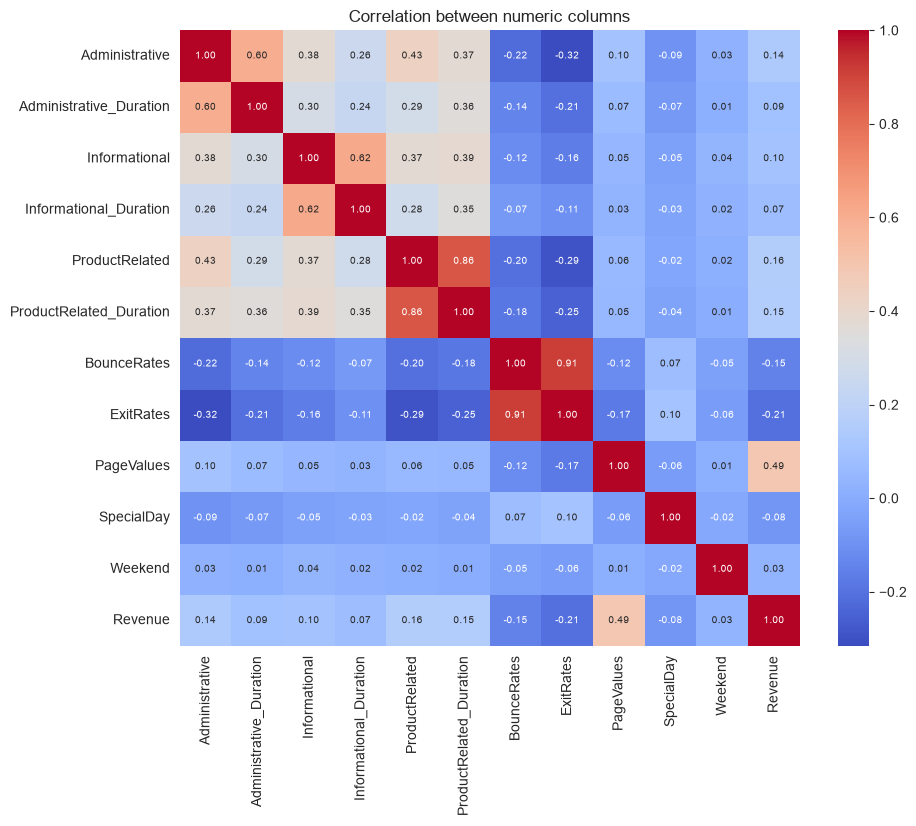

In [15]:
plt.figure(figsize=(10, 8))
corr_cols = num_cols + ["SpecialDay", "Weekend", "Revenue"]
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 7})
plt.title("Correlation between numeric columns")
plt.show()

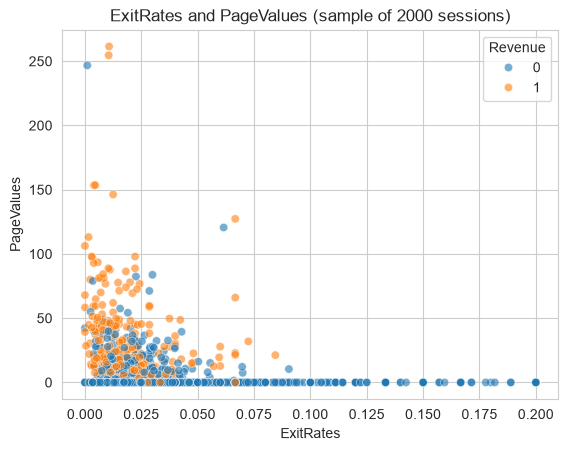

In [16]:
sample = df.sample(2000, random_state=RANDOM_STATE)
sns.scatterplot(data=sample, x="ExitRates", y="PageValues", hue="Revenue", alpha=0.6)
plt.title("ExitRates and PageValues (sample of 2000 sessions)")
plt.show()

### EDA insights

1. Only about 15% of the sessions end in a purchase. Accuracy would be misleading, so we focus on ROC-AUC, recall and F1.
2. `PageValues` is the strongest signal. When it is 0, purchases are rare. When it is above 0, the purchase rate is much higher.
3. High `ExitRates` and `BounceRates` go with fewer purchases. Our guess is that visitors who leave fast are not interested.
4. The purchase rate changes a lot between months. November looks like the best month and February the weakest.
5. New visitors buy more often than returning visitors. Weekend visits make only a small difference.

## 4. Preprocessing

Steps:

1. Remove duplicate rows, so the same session can not be in both train and test.
2. Drop `OperatingSystems`, `Browser`, `Region` and `TrafficType`. They are only codes, they are hard to fill in for a user and we do not need them for the app form.
3. Split the data before fitting anything. We keep 20% for the final test, with the same share of buyers in both parts.
4. Build one pipeline: feature step, imputing, scaling and one-hot encoding. Everything is fitted on the training data only.

In [17]:
df = df.drop_duplicates()
df = df.drop(columns=["OperatingSystems", "Browser", "Region", "TrafficType"])
print("Shape after cleaning:", df.shape)

Shape after cleaning: (12205, 14)


In [18]:
X = df.drop(columns=["Revenue"])
y = df["Revenue"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Purchase rate in train:", round(y_train.mean(), 3), " in test:", round(y_test.mean(), 3))

Train: (9764, 13)  Test: (2441, 13)
Purchase rate in train: 0.156  in test: 0.156


The feature step is in `helpers.py`, so the web app uses exactly the same code. It sets negative durations to 0, adds `TotalPages` and `TotalDuration`, and applies `log1p` to the counts and durations to reduce the effect of very large values. We keep the outlier rows because long sessions are real behavior.

In [19]:
print(inspect.getsource(add_features))

def add_features(X):
    """Clean durations, add total columns and log transform the skewed columns."""
    X = X.copy()

    # a duration can not be negative, so we set those values to 0
    for col in DURATION_COLS:
        X[col] = X[col].clip(lower=0)

    # new features
    X["TotalPages"] = X[COUNT_COLS].sum(axis=1)
    X["TotalDuration"] = X[DURATION_COLS].sum(axis=1)

    # log1p makes very large values smaller (outliers)
    for col in COUNT_COLS + DURATION_COLS + ["TotalPages", "TotalDuration"]:
        X[col] = np.log1p(X[col])

    return X



In [20]:
numeric_cols = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
                "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues",
                "SpecialDay", "Weekend", "TotalPages", "TotalDuration"]
categorical_cols = ["Month", "VisitorType"]

numeric_steps = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_steps = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_steps, numeric_cols),
    ("cat", categorical_steps, categorical_cols),
])


def make_pipeline(model):
    # full pipeline: features -> preprocessing -> model
    return Pipeline([
        ("features", FunctionTransformer(add_features)),
        ("prep", clone(preprocessor)),
        ("model", model),
    ])

## 5. Modeling

We use a baseline that always predicts the most common class (no purchase). Then we test three models from the course:

- Logistic Regression: simple and easy to explain.
- Random Forest: many decision trees together.
- Gradient Boosting: trees built one after another, each one fixing the errors of the last.

All models are compared with 5-fold stratified cross-validation on the training set only.

In [21]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

rows = []
for name, model in models.items():
    scores = cross_validate(make_pipeline(model), X_train, y_train, cv=cv,
                            scoring=["accuracy", "roc_auc", "recall", "f1"])
    rows.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
    })

cv_results = pd.DataFrame(rows).set_index("Model").round(3)
cv_results

,Accuracy,ROC-AUC,Recall,F1
Model,,,,
Baseline,0.844,0.500,0.000,0.000
Logistic Regression,0.845,0.902,0.772,0.609
Random Forest,0.893,0.926,0.735,0.683
Gradient Boosting,0.901,0.929,0.588,0.649


The baseline has a high accuracy but a recall of 0, because it never finds a buyer. This is why accuracy is not our main metric. The three models can be compared with ROC-AUC and F1.

## 6. Tuning and validation

We tune each model with grid search and 5-fold cross-validation on the training set. The score used is ROC-AUC. The test set is not used here.

In [22]:
param_grids = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10]},
    "Random Forest": {"model__n_estimators": [100, 300],
                      "model__max_depth": [6, 10, None],
                      "model__min_samples_leaf": [1, 5]},
    "Gradient Boosting": {"model__n_estimators": [100, 200],
                          "model__learning_rate": [0.05, 0.1],
                          "model__max_depth": [2, 3]},
}

best_models = {}
tuned_rows = []

for name, grid in param_grids.items():
    search = GridSearchCV(make_pipeline(models[name]), grid, cv=cv, scoring="roc_auc", n_jobs=-1)
    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    tuned_rows.append({
        "Model": name,
        "Best CV ROC-AUC": round(search.best_score_, 3),
        "Best parameters": search.best_params_,
    })
    print(name, "done")

tuned_results = pd.DataFrame(tuned_rows).set_index("Model")
tuned_results

Logistic Regression done
Random Forest done
Gradient Boosting done


,Best CV ROC-AUC,Best parameters
Model,,
Logistic Regression,0.902,{'model__C': 1}
Random Forest,0.931,"{'model__max_depth': None, 'model__min_samples_leaf': 5, 'model__n_estimators': 300}"
Gradient Boosting,0.930,"{'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 100}"


In [23]:
best_name = tuned_results["Best CV ROC-AUC"].astype(float).idxmax()
final_model = best_models[best_name]
print("Selected model:", best_name)

Selected model: Random Forest


We select the model with the best cross-validation ROC-AUC.

### Choosing the threshold

The model gives a probability of purchase. The usual cut-off of 0.5 is not good when the classes are imbalanced. We try many cut-offs and take the one with the best F1, using cross-validated predictions on the training set only.

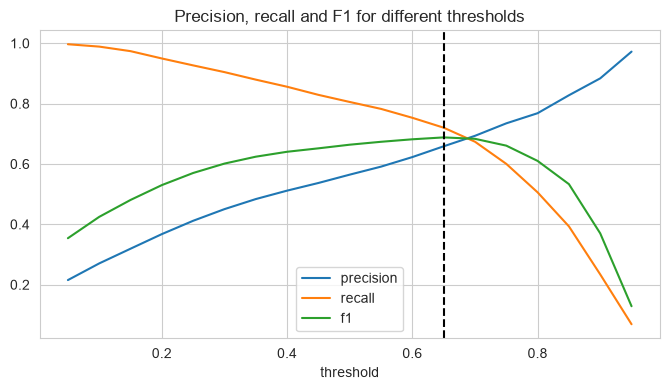

Chosen threshold: 0.65


In [24]:
train_probs = cross_val_predict(final_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

rows = []
for t in np.arange(0.05, 0.96, 0.05):
    pred = (train_probs >= t).astype(int)
    rows.append({
        "threshold": round(t, 2),
        "precision": precision_score(y_train, pred, zero_division=0),
        "recall": recall_score(y_train, pred),
        "f1": f1_score(y_train, pred),
    })

threshold_table = pd.DataFrame(rows)
best_threshold = float(threshold_table.loc[threshold_table["f1"].idxmax(), "threshold"])

threshold_table.set_index("threshold")[["precision", "recall", "f1"]].plot(figsize=(8, 4))
plt.axvline(best_threshold, color="black", linestyle="--")
plt.title("Precision, recall and F1 for different thresholds")
plt.show()

print("Chosen threshold:", best_threshold)

## 7. Evaluation

Now we use the test set for the first time. We compare the final model with the baseline.

In [25]:
test_probs = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_probs >= best_threshold).astype(int)

baseline = make_pipeline(DummyClassifier(strategy="most_frequent")).fit(X_train, y_train)
base_probs = baseline.predict_proba(X_test)[:, 1]
base_pred = baseline.predict(X_test)


def get_scores(y_true, pred, probs):
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred),
        "F1": f1_score(y_true, pred),
        "ROC-AUC": roc_auc_score(y_true, probs),
    }


test_results = pd.DataFrame({
    "Baseline": get_scores(y_test, base_pred, base_probs),
    best_name: get_scores(y_test, test_pred, test_probs),
}).T.round(3)

test_results

,Accuracy,Precision,Recall,F1,ROC-AUC
Baseline,0.844,0.000,0.000,0.000,0.500
Random Forest,0.895,0.648,0.717,0.681,0.929


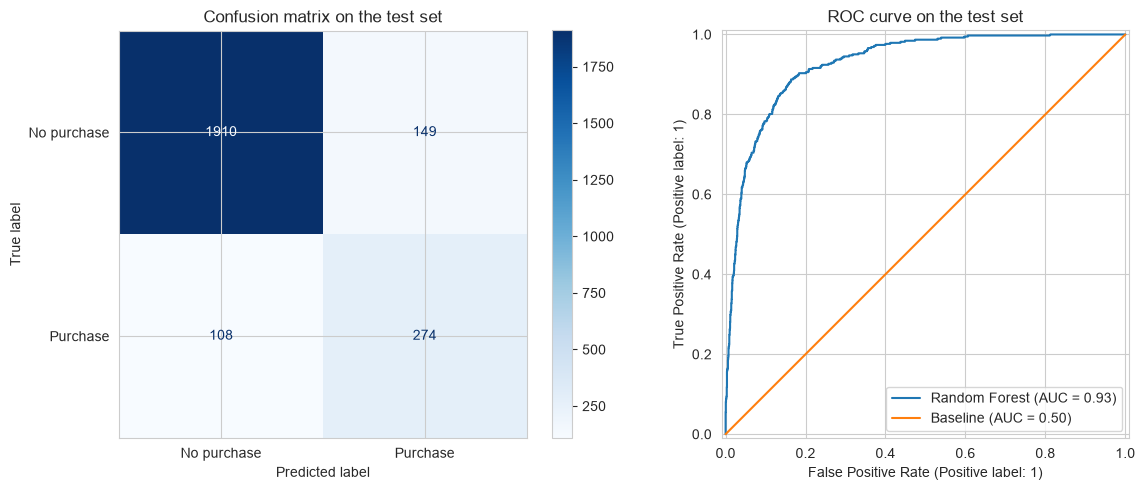

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["No purchase", "Purchase"],
                                        cmap="Blues", ax=axes[0])
axes[0].set_title("Confusion matrix on the test set")

RocCurveDisplay.from_predictions(y_test, test_probs, name=best_name, ax=axes[1])
RocCurveDisplay.from_predictions(y_test, base_probs, name="Baseline", ax=axes[1])
axes[1].set_title("ROC curve on the test set")

plt.tight_layout()
plt.show()

In [27]:
print(classification_report(y_test, test_pred, target_names=["No purchase", "Purchase"]))

              precision    recall  f1-score   support

 No purchase       0.95      0.93      0.94      2059
    Purchase       0.65      0.72      0.68       382

    accuracy                           0.89      2441
   macro avg       0.80      0.82      0.81      2441
weighted avg       0.90      0.89      0.90      2441



The baseline never finds a buyer, so its recall is 0. Our model finds a large part of the buyers, and its ROC-AUC is far above the 0.5 of the baseline. It is not perfect: some buyers are missed and some visitors get a wrong "will buy".

### Error analysis

We split the test sessions into four groups and compare their average values.

In [28]:
errors = X_test.copy()
errors["actual"] = y_test
errors["predicted"] = test_pred
errors["result"] = np.select(
    [(errors["actual"] == 1) & (errors["predicted"] == 1),
     (errors["actual"] == 0) & (errors["predicted"] == 0),
     (errors["actual"] == 0) & (errors["predicted"] == 1)],
    ["True positive", "True negative", "False positive"],
    default="False negative")

print(errors["result"].value_counts())
print()
errors.groupby("result")[["PageValues", "ExitRates", "BounceRates", "ProductRelated", "ProductRelated_Duration"]].mean().round(2)

result
True negative     1910
True positive      274
False positive     149
False negative     108
Name: count, dtype: int64



,PageValues,ExitRates,BounceRates,ProductRelated,ProductRelated_Duration
result,,,,,
False negative,3.61,0.03,0.01,54.40,2099.84
False positive,21.88,0.02,0.01,55.15,2106.44
True negative,0.52,0.05,0.02,26.14,974.60
True positive,36.20,0.02,0.00,49.85,1975.77


Missed buyers (false negatives) usually look like non-buyers, for example they have a low `PageValues` and a higher `ExitRates`. The model can not find them from these columns alone. The false positives look like buyers but did not buy, which is hard to avoid with this kind of data.

## 8. Business insight

First we check which columns matter most. We use permutation importance on the test set: we shuffle one column and see how much the ROC-AUC drops.

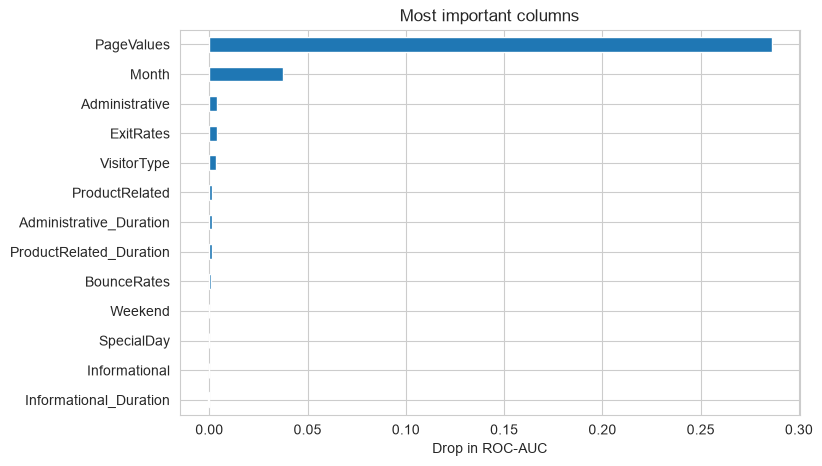

In [29]:
imp = permutation_importance(final_model, X_test, y_test, scoring="roc_auc",
                             n_repeats=5, random_state=RANDOM_STATE)
importance = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()

importance.plot(kind="barh", figsize=(8, 5))
plt.xlabel("Drop in ROC-AUC")
plt.title("Most important columns")
plt.show()

Now we turn the probability into an action. A visitor with a probability above the threshold gets no action. Between half of the threshold and the threshold we show a coupon. Below that we open the chat assistant. We check this rule on the test set.

In [30]:
actions = pd.Series([suggest_action(p, best_threshold) for p in test_probs])
check = pd.DataFrame({"action": actions, "bought": y_test.values})

action_table = check.groupby("action").agg(sessions=("bought", "size"), purchase_rate=("bought", "mean")).round(3)
action_table

,sessions,purchase_rate
action,,
No action,423,0.648
Show chat,1689,0.022
Show coupon,329,0.216


In [31]:
scores = test_results.loc[best_name]
top3 = importance.sort_values(ascending=False).head(3).index.tolist()

print("Best model:", best_name)
print("ROC-AUC on the test set:", round(scores["ROC-AUC"], 3))
print("Recall: the model finds", round(scores["Recall"] * 100), "% of the real buyers")
print("Precision: when it says 'will buy', it is right", round(scores["Precision"] * 100), "% of the time")
print("Most important columns:", ", ".join(top3))

Best model: Random Forest
ROC-AUC on the test set: 0.929
Recall: the model finds 72 % of the real buyers
Precision: when it says 'will buy', it is right 65 % of the time
Most important columns: PageValues, Month, Administrative


### What the results mean

The model gives each session a purchase probability. We use it to choose an action:

- High probability: show nothing. These visitors are likely to buy anyway, so a discount would be wasted.
- Middle probability: show a coupon. These visitors are undecided.
- Low probability: open the chat assistant. These visitors are unlikely to buy, and a chat costs less than a discount.

The table above shows that the three groups have different purchase rates, so the probability is useful.

### What the company should do next

- Run an A/B test on the coupon group before using it for all visitors. This shows the real effect on sales and the real cost of the discounts.
- Change the threshold if the cost of a coupon or the value of a sale changes.
- Train the model again every few months with new data.

### Limitations

- The data comes from one shop and covers about one year.
- `PageValues` is calculated by the site. It must be available in real time for the model to work live.
- The model shows who looks like a buyer. It does not prove that a coupon makes them buy.
- Two models use class weights, so the probabilities are not exact chances. We treat them as a score.
- We removed four code columns, which may cost a little accuracy.

## 9. Save the model for the web app

We save the full pipeline and the threshold. The web app (`app.py`) loads both files.

In [32]:
joblib.dump(final_model, "purchase_model.joblib")

with open("threshold.json", "w") as f:
    json.dump({"threshold": best_threshold}, f)

print("Saved purchase_model.joblib and threshold.json")
print("scikit-learn version:", sklearn.__version__)

Saved purchase_model.joblib and threshold.json
scikit-learn version: 1.9.1


In [33]:
# quick check: load the file again and predict one session
loaded = joblib.load("purchase_model.joblib")
one_session = X_test.iloc[[0]]

print("Loaded model:", round(loaded.predict_proba(one_session)[0, 1], 4))
print("Original model:", round(final_model.predict_proba(one_session)[0, 1], 4))

Loaded model: 0.1423
Original model: 0.1423


To start the app, run `streamlit run app.py` in the same folder. Use the scikit-learn version printed above in `requirements.txt`, so the saved model loads without problems when the app is deployed.